In [1]:
import numpy as np
import matplotlib.pyplot as plt

import sys
# sys.path.append("..")

import scipy.sparse as sps
from scipy.sparse.linalg import cg as sp_cg


from trips.test_problems.Tomography import Tomography
import astra

import jlinops

import numpy as np
import math

from jlinops.base import _CustomLinearOperator
# from .util import get_device

# from ias import IASSolver

from trips.utilities.phantoms import shepp_logan

from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import FormatStrFormatter

import matplotlib as mpl
# mpl.rcParams['text.usetex'] = True
# mpl.rc('text.latex', preamble=r'\usepackage{amsmath}')


from PIL import Image
import numpy as np

CMAP = "gray"

from msolver import MMGKS, IASGKS

# Test problem

In [2]:
np.random.seed(0)
theta_max = np.pi
#Tomo = Tomography (geom="fanflat", CommitCrime=True, theta_max=theta_max)
#Tomo = Tomography (geom="fanflat", CommitCrime=True)
Tomo = Tomography (geom="parallel", CommitCrime=False, theta_max=theta_max)
views = 50
noise_percent = 0.03 # percent of maximum of noiseless signal A x_true
N = 100

x_true = shepp_logan(N)
img_shape = x_true.shape
nx, ny = x_true.shape
(F , b_true , p , q , AforMatrixOperation ) = Tomo.gen_data( x_true , nx , ny , views )

noise_stdev = noise_percent*np.amax(b_true)
noise_var = noise_stdev**2
print(f"Noise level: {noise_percent}")
print(f"Noise stdev: {noise_stdev}")
print(f"Noise var: {noise_var}")


b_noisy = b_true.flatten() + noise_stdev*np.random.normal(size=b_true.flatten().shape)
b_noisy_shaped = b_noisy.reshape((p,q))
noisy_signal = b_noisy.flatten()
m, n = F.shape


# Define linear operator implementing A
_matvec_fn = lambda x: F.matvec(x)
_rmatvec_fn = lambda x: F.rmatvec(x)
A = _CustomLinearOperator( (m,n), _matvec_fn, _rmatvec_fn, device="cpu")

# Underdetermined rate:
underdetermined_rate = noisy_signal.size/(nx*ny)
print(f"Underdetermined rate: {underdetermined_rate}")

settings
no crime
Noise level: 0.03
Noise stdev: 0.8010007095336914
Noise var: 0.6416021366734771
Underdetermined rate: 0.705


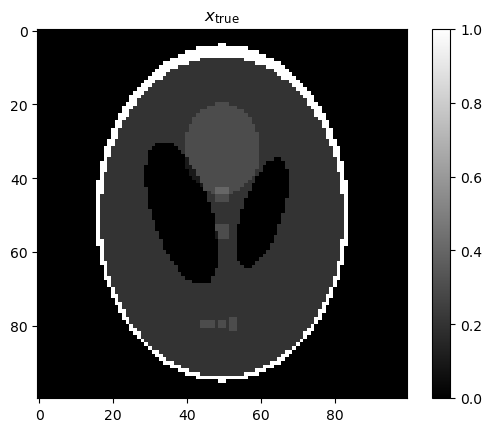

In [3]:
plt.imshow(x_true.reshape((nx,ny)), cmap=CMAP)
plt.title("$x_{\\text{true}}$")
plt.colorbar()
plt.show()

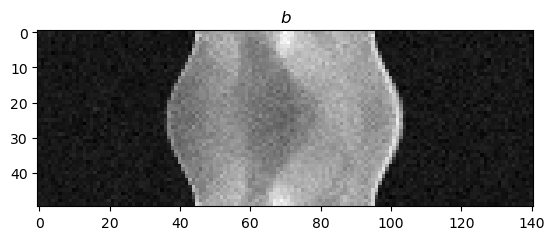

In [4]:
plt.imshow(b_noisy_shaped, cmap=CMAP)
plt.title("$b$")
plt.show()

In [5]:
# fbp_recon = Tomo.A.reconstruct("SIRT", noisy_signal, iterations=200)
fbp_recon = Tomo.A.reconstruct("FBP", noisy_signal, iterations=1)

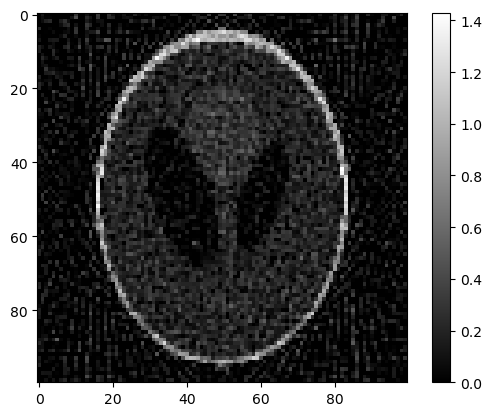

In [6]:
plt.imshow(np.clip(fbp_recon, a_min=0.0, a_max=None), cmap=CMAP)
plt.colorbar()
plt.show()

In [7]:
# W = np.ones(n)/np.linalg.norm(np.ones(n))
# W = jlinops.MatrixLinearOperator(W)

# R = jlinops.Neumann2D(img_shape)
# def Rpinv_factory(theta, *args, **kwargs):
#     return jlinops.CGWeightedNeumann2DPinvOperator(img_shape, weights=1.0/np.sqrt(theta), tol=1e-4, *args, **kwargs)

# #tol = 1e-2
# pdata = {
#     "W": W,
#     "Rpinv_factory": Rpinv_factory,
# }

# # Initialize everything at the least-squares reconstruction?
# x0, _ = sp_cg( (F.T @ F) + 7*1e2*(R.T @ R), F.T @ noisy_signal, tol=1e-5  )
# x0 = np.clip(x0, a_min=0.0, a_max=None)

# plt.imshow(x0.reshape(img_shape), cmap=CMAP)
# plt.colorbar()
# plt.show()

# GKS method (GKS)

In [8]:
q = 1.0
epsilon = 1e-3
weight_params = {
    "q": q,
    "epsilon": epsilon,
}

In [9]:
jlinops.build_neumann2d_sparse_matrix(img_shape)

<20000x10000 sparse matrix of type '<class 'numpy.float64'>'
	with 39600 stored elements in COOrdinate format>

In [10]:
# Set method
method = "dp"

Lmat = jlinops.build_neumann2d_sparse_matrix(img_shape)
L = jlinops.Neumann2D(img_shape)

# Pseudoinverse factory
def Lpinv_factory(wr):
    Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
    delta = 1e-15
    for j in range(10):
        try:
            return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=delta)
        except:
            delta *= 10
    return None


K = np.ones(n)/np.linalg.norm(np.ones(n))
K = jlinops.MatrixLinearOperator(K)

#L = jlinops.Neumann2D(img_shape)
# def Lpinv_factory(w, *args, **kwargs):
#     return jlinops.CGWeightedNeumann2DPinvOperator(img_shape, weights=w, tol=1e-4, *args, **kwargs)


#err_norm_sq = len(b) # in expectation

# Build solver
mmgks_solver = MMGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

In [11]:
data = mmgks_solver.solve(n_iter=80, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

1e-14
6.198654036395126
5.674979092971411
6.150039152876368
6.820535210069385
7.230220210967495
7.538306085828913
7.6491456755701535
7.850154735672201
8.060651352807712
8.165977458779167
8.33721887627324
8.376757958031806
8.450607578984572
8.491567461778049
8.530389459843562
8.536787519033462
8.546433477791053
8.553454948746964
8.556779901605829
8.558616742321766
8.559580085530001
8.558352268192447
8.557482136641754
8.55706706685717
8.558890186307899
8.557545475182879
8.555823849893443
8.55538056428298
8.555054326035938
8.554066368643202
8.555495409214865
8.55699995185369
8.556592860549461
8.557089542732832
8.5552222525411
8.549243773156464
8.551827213738967
8.550769141677927
8.549368980366745
8.550633827503624
8.55099247614797
8.549678955573098
8.54893678431005
8.551490562958037
8.55063117540906
8.553473088148666
8.551560852363854
8.5511377980972
8.550168059633547
8.54974417020398
8.54935854293522
8.54650558486589
8.547237150685604
8.54530426812117
8.54505081245748
8.547168171557818
8

In [12]:
pdata = mmgks_solver.solve_with_priorconditioning(n_iter=80, init_dim=8, x0=None, lambdah0=1e0, lambdah_min=1e-14, lambdah_max=1e7,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.02})

1
[  248.41608618   349.35140383 -1089.12840586 ... -1343.30107346
  -506.88191835     0.        ]
2
[-1.54343266e-04 -1.78036617e-04 -5.96320633e-04 ... -1.37723477e-04
 -2.46273070e-05  0.00000000e+00]
3
[-2.08334127e-04 -2.52058495e-04 -4.87350492e-04 ...  4.04774372e-05
  5.53591753e-05  0.00000000e+00]
4
[-2.14532964e-04 -2.60690509e-04 -4.71840512e-04 ...  7.54271635e-05
  7.06777924e-05  0.00000000e+00]
5
[-2.13854561e-04 -2.59640887e-04 -4.73081091e-04 ...  8.83594715e-05
  7.61866609e-05  0.00000000e+00]
6
[-2.11829919e-04 -2.56711406e-04 -4.77092379e-04 ...  9.81193247e-05
  8.02791853e-05  0.00000000e+00]
7
[-2.09380223e-04 -2.53197580e-04 -4.81649015e-04 ...  1.07818844e-04
  8.43225541e-05  0.00000000e+00]


1e-14


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/msolver.py:509: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
4.426097878256061
5.091989993857941
6.1391932453395635
7.097403603740272
7.828110862788637
8.284353702376322
8.415521430035072
8.50767060159583
8.490216117522046
8.652285586251313
8.633698485255763
8.581113570457415
8.742132390046226
8.740008574527865
8.792871478258315
8.823882187435172
8.85384139789005
8.858955629525807
8.872198064981522
8.884775304351416
8.89628082768569
8.911823527085335
8.919386178797641
8.926493362407333
8.925520150709865
8.934326344423567
8.937816383973145
8.945658576100481
8.947997079285374
8.950372579681416
8.949368277403329
8.956256007567251
8.954731813811318
8.957845291126958
8.960264399191233
8.960490165579404
8.962103360451469
8.962199837647134
8.962488896720423
8.96290650444988
8.963836928778706
8.964632113366662
8.96516577941272
8.965521232498725
8.96560411172937
8.9658709001575
8.966080474123315
8.966320668251926
8.966698546265553
8.966793968784629

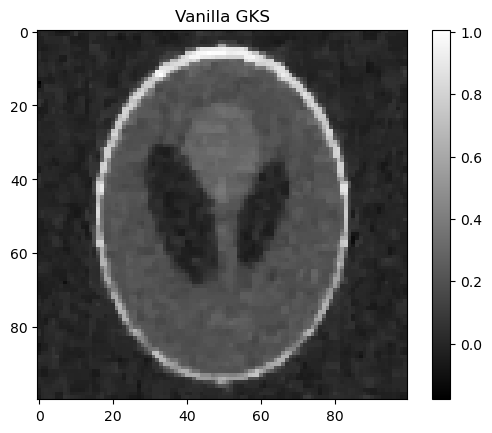

In [13]:
plt.imshow(data["x"].reshape((nx,ny)), cmap="gray")
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

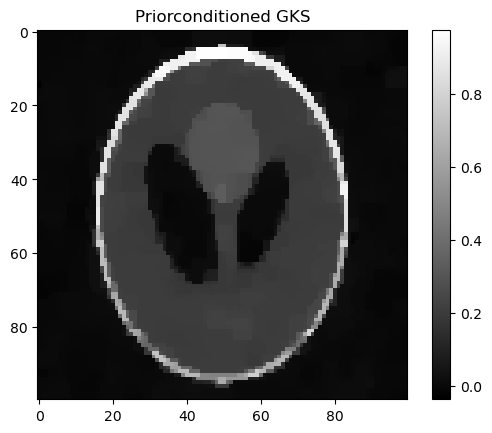

In [14]:
plt.imshow(pdata["x"].reshape((nx,ny)), cmap="gray")
plt.title("Priorconditioned GKS")
plt.colorbar()
plt.show()

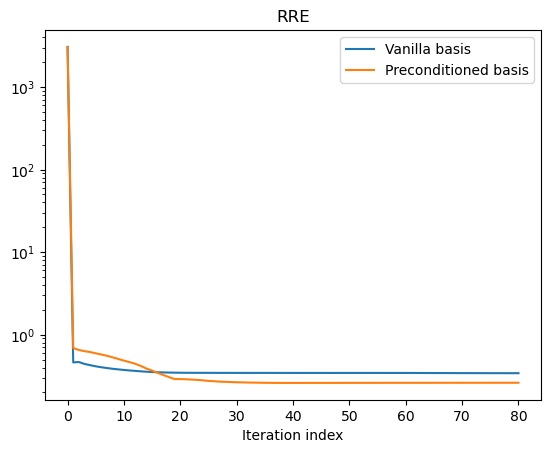

In [15]:
plt.semilogy(data["rre_history"], label="Vanilla basis")
plt.semilogy(pdata["rre_history"], label="Preconditioned basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

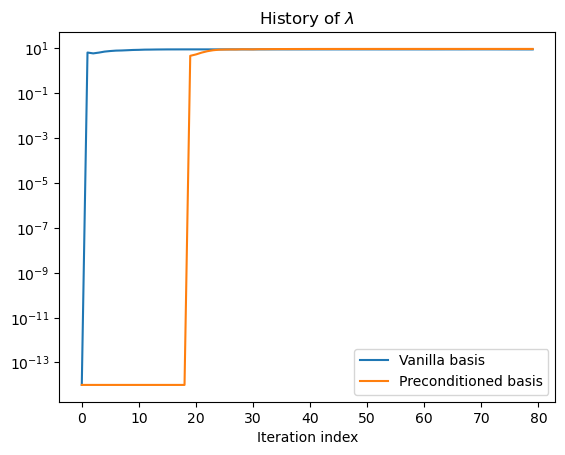

In [16]:
plt.semilogy(data["lambda_history"], label="Vanilla basis")
plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

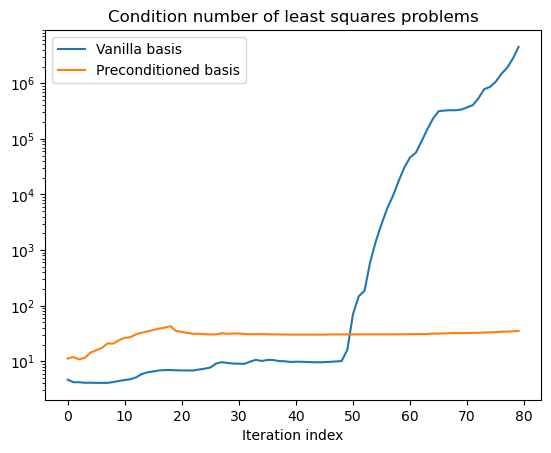

In [17]:
plt.semilogy(data["cond_ests"], label="Vanilla basis")
plt.semilogy(pdata["cond_ests"], label="Preconditioned basis")
plt.title("Condition number of least squares problems")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

# Initialize nonconvex IAS with MM?

In [18]:
weight_params2 = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}

In [19]:
# Build solver
iasgks_solver = IASGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

In [20]:
# data = iasgks_solver.solve(n_iter=120, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-14, lambdah_max=1e7,
#                                     regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
#                                     regparam_kwargs={"eta":1.01})

In [23]:
pdata2 = iasgks_solver.solve_with_priorconditioning(n_iter=120, init_dim=8, x0=pdata["x"], lambdah0=pdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=weight_params2,
                                                 regparam_kwargs={"eta":1.01})

1
[ -28.11254935  -24.37772811  -16.75130792 ... -121.27367822  -56.97535164
    0.        ]
2
[-4.07425974e-04 -4.11516980e-04 -4.01260424e-04 ...  6.33915771e-05
  4.59251318e-05  0.00000000e+00]
3
[-0.00039687 -0.00040902 -0.00039545 ...  0.00032847  0.00018114
  0.        ]
4
[-0.00039265 -0.0004061  -0.00039183 ...  0.00037551  0.00020495
  0.        ]
5
[-0.00039213 -0.0004057  -0.00039138 ...  0.00038657  0.00021049
  0.        ]
6
[-0.00039225 -0.00040575 -0.00039149 ...  0.00039156  0.00021295
  0.        ]
7
[-0.00039246 -0.00040584 -0.00039168 ...  0.00039556  0.00021491
  0.        ]


1e-14


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/msolver.py:509: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
9.42979617360707
5.00101404842238
13.193084216337283
15.866075760213402
17.36622851477889
23.20431595761511
27.843009948289623
31.19580196405275
34.19798159263382
37.44088889120566
39.903820750698394
42.04093028594562
44.185598096224574
46.269751274534954
48.08423257506967
50.36786050460521
52.514030365492864
54.8936878239996
57.383964171910975
59.71785538915851
61.336634427952156
62.425214830014376
63.107132993153456
64.13645142499001
65.01503290060019
66.1051372368868
67.08703979849214
68.04654326145166
69.01519611668445
70.03784392840787
71.13226903370163
72.17128469002536
72.969742357801
73.83575816347651
74.79665714606071
75.82994422270959
76.54057159203673
77.10112937966073
77.79416644462103
78.28556783060661
78.65455714938737
79.06409389659436
79.5282527417275
79.8947925843818
80.27362757863773
80.65545942881614
81.0588

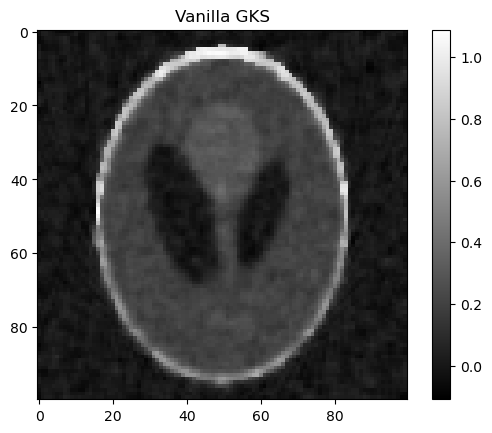

In [84]:
plt.imshow(data["x"].reshape((nx,ny)), cmap="gray")
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

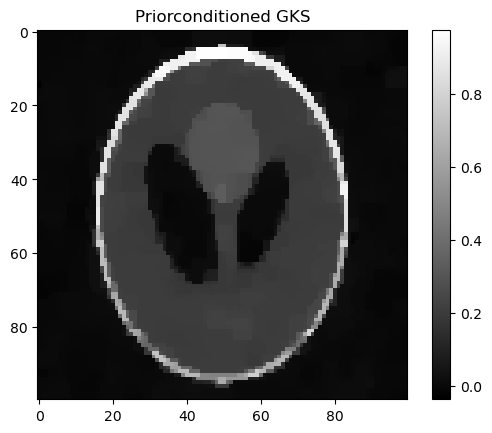

In [27]:
plt.imshow(pdata["x"].reshape((nx,ny)), cmap="gray")
plt.title("Priorconditioned GKS")
plt.colorbar()
plt.show()

In [24]:
from matplotlib.backends.backend_pdf import PdfPages

In [28]:
# Create a PDF file
pdf_filename = "tomo_ias_preconditioned_basis_warmstart.pdf"
images = [ ( pdata2["V"][:nx*ny,j].reshape((nx,ny)), pdata2["V"][nx*ny:,j].reshape((nx,ny))   ) for j in range(pdata2["V"].shape[1]) ]
with PdfPages(pdf_filename) as pdf:
    for i, (im1, im2) in enumerate(images):
        plt.figure(figsize=(10, 5))  # Create a figure with an appropriate size
        
        # Plot the first image (im1)
        plt.subplot(1, 2, 1)  # 1 row, 2 columns, 1st subplot
        plt.imshow(im1, cmap='viridis', aspect='auto')
        plt.colorbar()  # Optional: Add a color bar to show the scale
        plt.title(f"Vertical portion of basis vector, {i+1}")

        # Plot the second image (im2)
        plt.subplot(1, 2, 2)  # 1 row, 2 columns, 2nd subplot
        plt.imshow(im2, cmap='plasma', aspect='auto')
        plt.colorbar()  # Optional: Add a color bar to show the scale
        plt.title(f"Horizontal portion of basis vector, {i+1}")
        
        # Save the current figure to the PDF
        pdf.savefig()
        plt.close()  # Close the figure to free up memory

print(f"Paired plots saved to {pdf_filename}")

Paired plots saved to tomo_ias_preconditioned_basis_warmstart.pdf


In [29]:
images = [ (pdata2["Lopinv"] @ pdata["V"][:,j]).reshape((nx,ny)) for j in range(pdata2["V"].shape[1]) ]
# Create a PDF file
pdf_filename = "tomo_ias_preconditioned_basis_transformed_warmstart.pdf"
with PdfPages(pdf_filename) as pdf:
    for i, array in enumerate(images):
        plt.figure()
        plt.imshow(array, cmap='viridis', aspect='auto')
        plt.colorbar()  # Optional: Add a color bar to show the scale
        plt.title(f"Array {i+1}")
        pdf.savefig()  # Save the current figure to the PDF
        plt.close()  # Close the figure to avoid memory issues

IndexError: index 88 is out of bounds for axis 1 with size 88